# What is EDA?
- EDA = Exploratory Data Analysis
- EDA means understanding and analyzing a dataset before building a Machine Learning model or making business decisions.

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/day34_retail_eda_dataset.csv")

In [43]:
df.head()

,Order_ID,Customer_Name,City,Category,Product,Quantity,Unit_Price_INR,Order_Status,Customer_Rating,Revenue_INR
0,3401,Anil,Hyderabad,Electronics,Laptop,1.0,55000,Delivered,4.5,55000
1,3402,Bhavya,Bengaluru,Accessories,Mouse,3.0,700,Delivered,4.2,2100
2,3403,Charan,Chennai,Accessories,Keyboard,2.0,1200,Cancelled,3.8,2400
3,3404,Divya,Hyderabad,Electronics,Monitor,1.0,14000,Delivered,4.7,14000
4,3405,Esha,Vijayawada,Accessories,Mouse,4.0,700,Delivered,4.1,2800


In [44]:
df.tail()

,Order_ID,Customer_Name,City,Category,Product,Quantity,Unit_Price_INR,Order_Status,Customer_Rating,Revenue_INR
36,3437,Mohan,Chennai,Accessories,Keyboard,3.0,1200,Cancelled,3.6,3600
37,3438,Sravya,Vijayawada,Electronics,Monitor,1.0,14000,Delivered,4.5,14000
38,3439,Gopal,Hyderabad,Accessories,Mouse,4.0,700,Delivered,4.0,2800
39,3440,Harika,Bengaluru,Electronics,Laptop,1.0,55000,Delivered,4.8,55000
40,3401,Anil,Hyderabad,Electronics,Laptop,1.0,55000,Delivered,4.5,55000


In [45]:
df.shape

(41, 10)

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         41 non-null     int64  
 1   Customer_Name    41 non-null     object 
 2   City             40 non-null     object 
 3   Category         41 non-null     object 
 4   Product          41 non-null     object 
 5   Quantity         40 non-null     float64
 6   Unit_Price_INR   41 non-null     int64  
 7   Order_Status     41 non-null     object 
 8   Customer_Rating  40 non-null     float64
 9   Revenue_INR      41 non-null     int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 3.3+ KB


In [47]:
df.columns

Index(['Order_ID', 'Customer_Name', 'City', 'Category', 'Product', 'Quantity',
       'Unit_Price_INR', 'Order_Status', 'Customer_Rating', 'Revenue_INR'],
      dtype='object')

In [48]:
df.describe()

,Order_ID,Quantity,Unit_Price_INR,Customer_Rating,Revenue_INR
count,41.000000,40.000000,41.000000,40.000000,41.000000
mean,3420.024390,2.125000,18297.560976,4.252500,21885.365854
std,11.938358,1.244217,23092.753060,0.370023,29033.149683
min,3401.000000,1.000000,700.000000,3.500000,1400.000000
25%,3410.000000,1.000000,700.000000,4.000000,2400.000000
50%,3420.000000,2.000000,1200.000000,4.250000,4800.000000
75%,3430.000000,3.000000,55000.000000,4.500000,55000.000000
max,3440.000000,5.000000,55000.000000,4.900000,110000.000000


In [49]:
df.dtypes

Order_ID             int64
Customer_Name       object
City                object
Category            object
Product             object
Quantity           float64
Unit_Price_INR       int64
Order_Status        object
Customer_Rating    float64
Revenue_INR          int64
dtype: object

In [50]:
df.isnull().sum()

Order_ID           0
Customer_Name      0
City               1
Category           0
Product            0
Quantity           1
Unit_Price_INR     0
Order_Status       0
Customer_Rating    1
Revenue_INR        0
dtype: int64

In [51]:
(df.isnull().sum()/len(df)*100).round(2)

Order_ID           0.00
Customer_Name      0.00
City               2.44
Category           0.00
Product            0.00
Quantity           2.44
Unit_Price_INR     0.00
Order_Status       0.00
Customer_Rating    2.44
Revenue_INR        0.00
dtype: float64

In [52]:
df.duplicated().sum()

np.int64(1)

In [53]:
df=df.drop_duplicates()
df.shape

(40, 10)

In [54]:
df["City"] = df["City"].fillna("Unknown")
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Customer_Rating"] = df["Customer_Rating"].fillna(df["Customer_Rating"].median())

In [55]:
df["Revenue_INR"].mean()

np.float64(21057.5)

In [56]:
df["Revenue_INR"].median()

np.float64(4200.0)

In [57]:
df["Revenue_INR"].max()

np.int64(110000)

In [58]:
df.groupby("City")["Revenue_INR"].sum()

City
Bengaluru     165000
Chennai       207700
Hyderabad     265100
Unknown         2800
Vijayawada    201700
Name: Revenue_INR, dtype: int64

In [59]:
df.groupby("City")["Revenue_INR"].mean()

City
Bengaluru     16500.0
Chennai       20770.0
Hyderabad     24100.0
Unknown        2800.0
Vijayawada    25212.5
Name: Revenue_INR, dtype: float64

In [60]:
df.groupby("City")["Revenue_INR"].max()

City
Bengaluru      55000
Chennai       110000
Hyderabad      55000
Unknown         2800
Vijayawada    110000
Name: Revenue_INR, dtype: int64

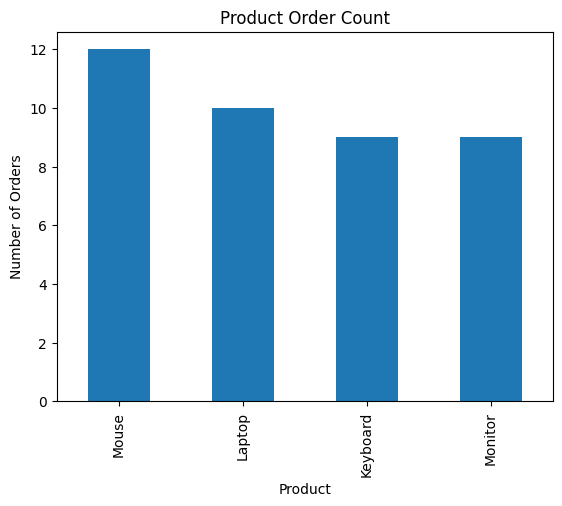

In [61]:
df["Product"].value_counts().plot(kind="bar")
plt.title("Product Order Count")
plt.xlabel("Product")
plt.ylabel("Number of Orders")
plt.show()

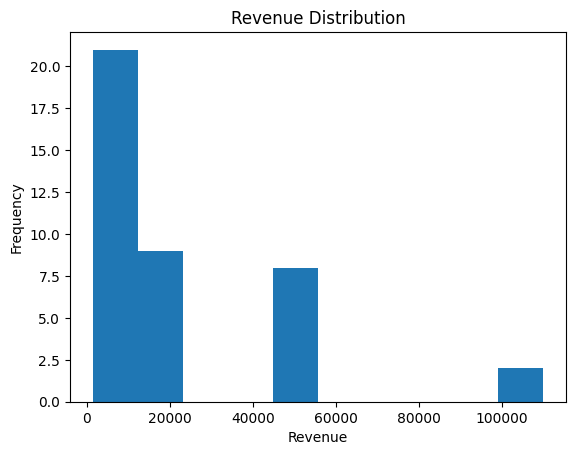

In [63]:
plt.hist(df["Revenue_INR"], bins=10)
plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

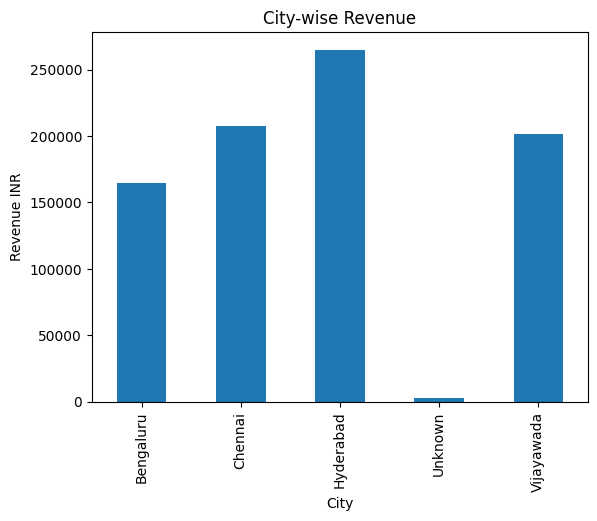

In [68]:
# City-wise revenue
city_revenue=df.groupby("City")["Revenue_INR"].sum()
city_revenue.plot(kind="bar")
plt.title("City-wise Revenue")
plt.xlabel("City")
plt.ylabel("Revenue INR")
plt.show()

# Correlation heatmap

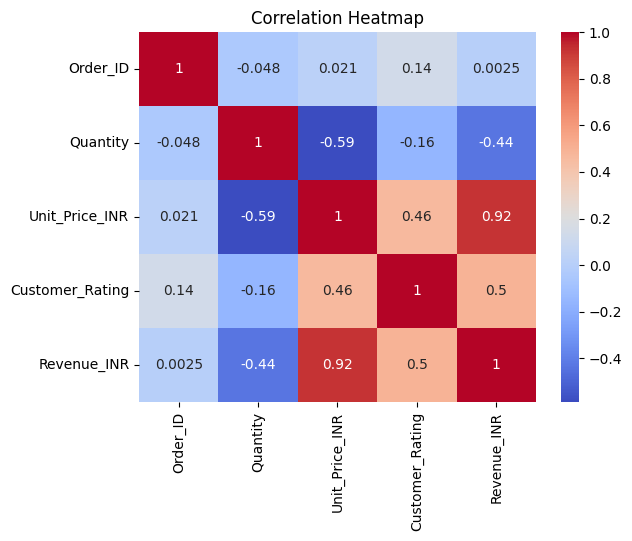

In [69]:
numeric_df = df.select_dtypes(include="number")
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()